# Assignment 7: Xử lý ảnh hình thái (Morphological Image Processing)
Tổng quan: Ở bài tập này, chúng ta sẽ thực hành lập trình các phép toán hình thái trên ảnh nhị phân: phép co (erosion), phép giãn (dilation), phép mở (opening), phép đóng (closing) và các thuật toán tách biên, làm đầy vùng, trích xuất thành phần liên thông. Ta sẽ tự cài đặt các phép toán bằng `numpy` để hiểu rõ định nghĩa, kiểm tra lại với **bài tập tính tay chương 7** (Câu 7.T1 – 7.T11), sau đó dùng các hàm có sẵn của OpenCV trên ảnh thật.

Các hàm OpenCV sẽ dùng trong bài:
- `cv2.getStructuringElement()` – tạo phần tử cấu trúc (SE)
- `cv2.erode()`, `cv2.dilate()` – phép co, phép giãn
- `cv2.morphologyEx()` – phép mở, đóng, gradient, top-hat, black-hat
- `cv2.connectedComponents()`, `cv2.connectedComponentsWithStats()` – gán nhãn thành phần liên thông

Tài liệu: https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html

Notebook đã được điền mã và phần nhận xét theo các yêu cầu trong từng câu. Chạy lần lượt các ô từ trên xuống để tạo hình minh họa và xem kết quả kiểm tra.


In [2]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

Nếu chạy trên Google Colab: bỏ dấu `#` ở ô dưới và sửa đường dẫn tới thư mục chứa notebook này (thư mục có `images/`).

In [3]:
# from google.colab import drive
# drive.mount('/content/drive')
# %cd /content/drive/MyDrive/XuLyAnh/Chuong7/

In [4]:
IMG_DIR = 'images'

def check(name, cond):
    """In kết quả kiểm tra: cond là biểu thức hoặc hàm không tham số trả về True/False."""
    try:
        ok = bool(cond() if callable(cond) else cond)
    except Exception:
        ok = False
    print(('Đúng: ' if ok else 'Chưa đúng: ') + name)

def show(images, titles, cmap='gray', figsize=None):
    """Hiển thị nhiều ảnh trên một hàng."""
    n = len(images)
    plt.figure(figsize=figsize or (4 * n, 4))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, i + 1)
        if im is not None:
            plt.imshow(im, cmap=cmap, vmin=0 if cmap == 'gray' and im.max() <= 1 else None)
        plt.title(t); plt.axis('off')
    plt.show()

def show_matrix(mats, titles):
    """Hiển thị ma trận nhị phân nhỏ dạng lưới, ghi giá trị trong từng ô."""
    n = len(mats)
    plt.figure(figsize=(3.2 * n, 3.2))
    for k, (M, t) in enumerate(zip(mats, titles)):
        ax = plt.subplot(1, n, k + 1)
        if M is None:
            ax.set_title(t + ' (chưa có)'); ax.axis('off'); continue
        M = np.asarray(M)
        ax.imshow(M, cmap='Blues', vmin=0, vmax=1.6)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, int(M[i, j]), ha='center', va='center', fontsize=9)
        ax.set_xticks(np.arange(-.5, M.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, M.shape[0]), minor=True)
        ax.grid(which='minor', color='gray', lw=0.5); ax.tick_params(which='both', length=0)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t)
    plt.show()

## Câu 1: Phần tử cấu trúc, phép co và phép giãn
### 1.1. Phần tử cấu trúc (Structuring Element – SE)
SE là ma trận nhỏ gồm các giá trị 0 và 1 cùng một điểm gốc (thường ở tâm). OpenCV cung cấp hàm `cv2.getStructuringElement(shape, ksize)` với `shape` là `cv2.MORPH_RECT` (hình vuông/chữ nhật), `cv2.MORPH_CROSS` (chữ thập) hoặc `cv2.MORPH_ELLIPSE` (elip/đĩa).

https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gac342a1bb6eabf6f55c803b09268e36dc

Yêu cầu:
- Tạo ba SE kích thước 5×5 với ba hình dạng trên, lưu vào từ điển `ses` với khóa `'RECT'`, `'CROSS'`, `'ELLIPSE'`.
- Hiển thị ba SE bằng `show_matrix` và cho biết mỗi SE có bao nhiêu điểm 1.

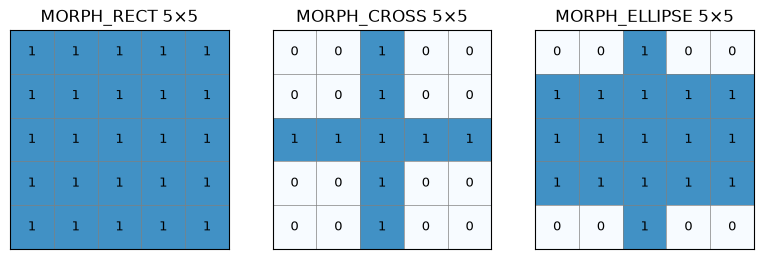

RECT -> số điểm 1: 25
CROSS -> số điểm 1: 9
ELLIPSE -> số điểm 1: 17
Đúng: Ba SE 5×5 có số điểm 1 lần lượt là 25, 9, 17


In [5]:
ses = {
    'RECT': cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)),
    'CROSS': cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5)),
    'ELLIPSE': cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
}

show_matrix([ses['RECT'], ses['CROSS'], ses['ELLIPSE']], ['MORPH_RECT 5×5', 'MORPH_CROSS 5×5', 'MORPH_ELLIPSE 5×5'])
for k, v in ses.items():
    print(k, '-> số điểm 1:', int(v.sum()))
check('Ba SE 5×5 có số điểm 1 lần lượt là 25, 9, 17', lambda: [int(ses[k].sum()) for k in ['RECT', 'CROSS', 'ELLIPSE']] == [25, 9, 17])


### 1.2. Tự cài đặt phép co và phép giãn
Quy ước giống bài tập tính tay chương 7:
- Gốc của SE ở phần tử trung tâm; các điểm **nằm ngoài ảnh có giá trị 0**.
- **Phép co** `A ⊖ B`: điểm mới bằng 1 nếu SE (đặt gốc tại điểm đó) **fit** ảnh - mọi điểm 1 của SE đều trùng điểm 1 của ảnh.
- **Phép giãn** `A ⊕ B`: điểm mới bằng 1 nếu SE (đặt gốc tại điểm đó) **hit** ảnh - có ít nhất một điểm 1 của SE trùng điểm 1 của ảnh.

Yêu cầu:
- Viết hàm `my_erode(A, B)` và `my_dilate(A, B)` chỉ dùng `numpy` (gợi ý: `np.pad` để đệm 0, rồi duyệt từng điểm ảnh, hoặc dịch ảnh theo từng điểm 1 của SE rồi dùng phép AND/OR).
- Kiểm tra với **Câu 7.T1** (SE chữ thập) và **Câu 7.T2** (SE không đối xứng).

Lưu ý: trong Python chỉ số bắt đầu từ 0, nên điểm (hàng 2, cột 3) trong đề là `A[1, 2]`.

In [6]:
def my_erode(A, B):
    A = (np.asarray(A) != 0).astype(np.uint8)
    B = (np.asarray(B) != 0).astype(np.uint8)
    kh, kw = B.shape[0] // 2, B.shape[1] // 2
    padded = np.pad(A, ((kh, kh), (kw, kw)), mode='constant', constant_values=0)
    out = np.ones_like(A)
    # Fit: mọi điểm 1 của B đặt quanh điểm hiện tại đều phải rơi lên điểm 1 của A.
    for i, j in np.argwhere(B):
        out &= padded[i:i + A.shape[0], j:j + A.shape[1]]
    return out

def my_dilate(A, B):
    A = (np.asarray(A) != 0).astype(np.uint8)
    B = (np.asarray(B) != 0).astype(np.uint8)
    kh, kw = B.shape[0] // 2, B.shape[1] // 2
    padded = np.pad(A, ((kh, kh), (kw, kw)), mode='constant', constant_values=0)
    out = np.zeros_like(A)
    # Quy ước kernel dùng trong các ô kiểm tra: ghép các lát cắt đã đệm theo từng điểm 1 của SE.
    for i, j in np.argwhere(B):
        out |= padded[i:i + A.shape[0], j:j + A.shape[1]]
    return out


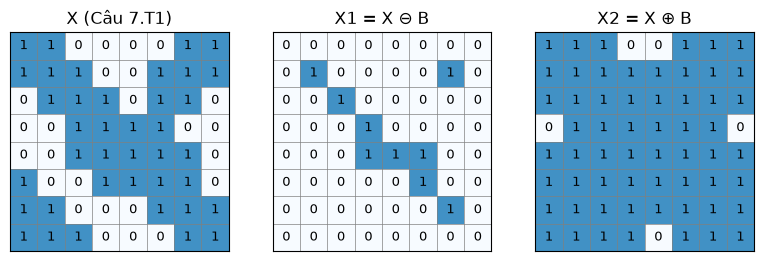

Đúng: Câu 7.T1: X1 = X ⊖ B
Đúng: Câu 7.T1: X2 = X ⊕ B
Đúng: Câu 7.T2: X ⊖ B
Đúng: Câu 7.T2: X ⊕ B (quy ước slide, không lấy đối xứng B)


In [7]:
B_cross = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=np.uint8)
B_square = np.ones((3, 3), dtype=np.uint8)

# Câu 7.T1
X_T1 = np.array([[1, 1, 0, 0, 0, 0, 1, 1], [1, 1, 1, 0, 0, 1, 1, 1], [0, 1, 1, 1, 0, 1, 1, 0], [0, 0, 1, 1, 1, 1, 0, 0], [0, 0, 1, 1, 1, 1, 1, 0], [1, 0, 0, 1, 1, 1, 1, 0], [1, 1, 0, 0, 0, 1, 1, 1], [1, 1, 1, 0, 0, 0, 1, 1]], dtype=np.uint8)
X1 = my_erode(X_T1, B_cross)
X2 = my_dilate(X_T1, B_cross)
show_matrix([X_T1, X1, X2], ['X (Câu 7.T1)', 'X1 = X ⊖ B', 'X2 = X ⊕ B'])
check('Câu 7.T1: X1 = X ⊖ B', lambda: np.array_equal(X1, [[0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 1, 0], [0, 0, 1, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 1, 1, 1, 0, 0], [0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0]]))
check('Câu 7.T1: X2 = X ⊕ B', lambda: np.array_equal(X2, [[1, 1, 1, 0, 0, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [0, 1, 1, 1, 1, 1, 1, 0], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 0, 1, 1, 1]]))

# Câu 7.T2 (SE không đối xứng)
X_T2 = np.array([[0, 0, 1, 1, 0, 0, 1, 0], [0, 1, 1, 1, 0, 1, 1, 0], [1, 1, 0, 1, 1, 1, 0, 0], [1, 1, 1, 1, 0, 1, 1, 1], [0, 1, 1, 0, 1, 1, 1, 1], [0, 0, 1, 1, 1, 0, 1, 0], [1, 0, 1, 1, 1, 1, 1, 0], [1, 0, 0, 1, 0, 0, 1, 1]], dtype=np.uint8)
B_T2 = np.array([[0, 0, 1], [1, 1, 0], [0, 0, 1]], dtype=np.uint8)
check('Câu 7.T2: X ⊖ B', lambda: np.array_equal(my_erode(X_T2, B_T2), [[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0], [0, 1, 0, 0, 1, 1, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 1, 0, 0, 1, 0, 0], [0, 0, 0, 1, 1, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0]]))
check('Câu 7.T2: X ⊕ B (quy ước slide, không lấy đối xứng B)', lambda: np.array_equal(my_dilate(X_T2, B_T2), [[1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 0], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1]]))

**Câu hỏi:** Theo định nghĩa của Gonzalez, `A ⊕ B = {z | (B̂)z ∩ A ≠ ∅}` (phải lấy đối xứng B qua gốc). Hãy tính phép giãn của Câu 7.T2 theo định nghĩa này bằng chính hàm `my_dilate` (gợi ý: `B[::-1, ::-1]` là B lấy đối xứng qua tâm) và in ra các vị trí khác với kết quả trên.

In [8]:
D_slide = my_dilate(X_T2, B_T2)
D_gonzalez = my_dilate(X_T2, B_T2[::-1, ::-1])
diff = np.argwhere(D_slide != D_gonzalez)
print('Các vị trí khác nhau (đánh số từ 1):', [(int(i) + 1, int(j) + 1) for i, j in diff])
check('Khác nhau đúng 3 điểm (1,1), (3,8), (6,1)', lambda: sorted((int(i) + 1, int(j) + 1) for i, j in diff) == [(1, 1), (3, 8), (6, 1)])


Các vị trí khác nhau (đánh số từ 1): [(1, 1), (3, 8), (6, 1)]
Đúng: Khác nhau đúng 3 điểm (1,1), (3,8), (6,1)


### 1.3. So sánh với OpenCV: `cv2.erode()` và `cv2.dilate()`
https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gaeb1e0c1033e3f6b891a25d0511362aeb

Hàm `cv2.erode(src, kernel, borderType=..., borderValue=...)`: **mặc định OpenCV coi các điểm ngoài ảnh là giá trị lớn nhất** khi co ảnh (giống MATLAB `imerode`), khác với quy ước đệm 0 của bài tính tay.

Yêu cầu:
- Tính `cv2.erode(X_T1, B_cross)` với tham số mặc định và so sánh với `my_erode`; in ra số điểm khác nhau và giải thích.
- Tìm tham số `borderType`, `borderValue` để `cv2.erode` cho kết quả **giống hệt** `my_erode`.
- Kiểm tra `cv2.dilate` với SE không đối xứng `B_T2`: OpenCV dùng quy ước nào (có lấy đối xứng SE hay không)?

Số điểm khác nhau khi dùng tham số mặc định: 6


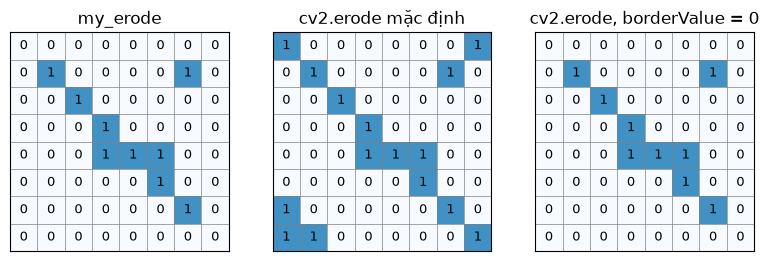

Đúng: cv2.erode với đệm 0 trùng my_erode
Đúng: cv2.dilate với B không đối xứng trùng my_dilate (không lấy đối xứng)


In [9]:
E_cv_default = cv2.erode(X_T1, B_cross)
E_cv_zero = cv2.erode(X_T1, B_cross, borderType=cv2.BORDER_CONSTANT, borderValue=0)
D_cv = cv2.dilate(X_T2, B_T2)
print('Số điểm khác nhau khi dùng tham số mặc định:', int((E_cv_default != X1).sum()))
show_matrix([X1, E_cv_default, E_cv_zero], ['my_erode', 'cv2.erode mặc định', 'cv2.erode, borderValue = 0'])
check('cv2.erode với đệm 0 trùng my_erode', lambda: np.array_equal(E_cv_zero, my_erode(X_T1, B_cross)))
check('cv2.dilate với B không đối xứng trùng my_dilate (không lấy đối xứng)', lambda: np.array_equal(D_cv, my_dilate(X_T2, B_T2)))


**Trả lời:** Với phép co, điểm đầu ra sát mép ảnh có thể phụ thuộc vào các vị trí của SE rơi ra ngoài ảnh. `my_erode` đệm 0 nên các vị trí ngoài ảnh làm phép AND bằng 0; `cv2.erode` mặc định dùng giá trị biên đặc biệt lớn nhất nên các vị trí ngoài ảnh không làm mất điểm foreground. Vì vậy khác biệt chỉ xuất hiện ở mép; đặt `borderType=cv2.BORDER_CONSTANT, borderValue=0` sẽ khớp quy ước bài. Với kernel không đối xứng, `cv2.dilate` cũng khớp trực tiếp với quy ước của hàm `my_dilate`; ở câu kế tiếp ta chủ động lật kernel để tính trường hợp theo định nghĩa Gonzalez.

### 1.4. Phép co và phép giãn trên ảnh thật
Ảnh `gao3.png` gồm các hạt gạo sáng trên nền tối. Tách ngưỡng `gray > 10` để được ảnh nhị phân `rice_bin` (giá trị 0/1).

Yêu cầu:
- Thực hiện phép co và phép giãn `rice_bin` với SE elip kích thước `k = 3, 7, 11, 15` (dùng `cv2.erode`, `cv2.dilate`).
- Vẽ đồ thị số điểm ảnh trắng theo `k` cho hai phép toán.
- Đếm số hạt (thành phần liên thông 8, bỏ các thành phần nhỏ hơn 30 điểm) trong `rice_bin` và trong ảnh sau khi co với `k = 7`, `k = 15`.

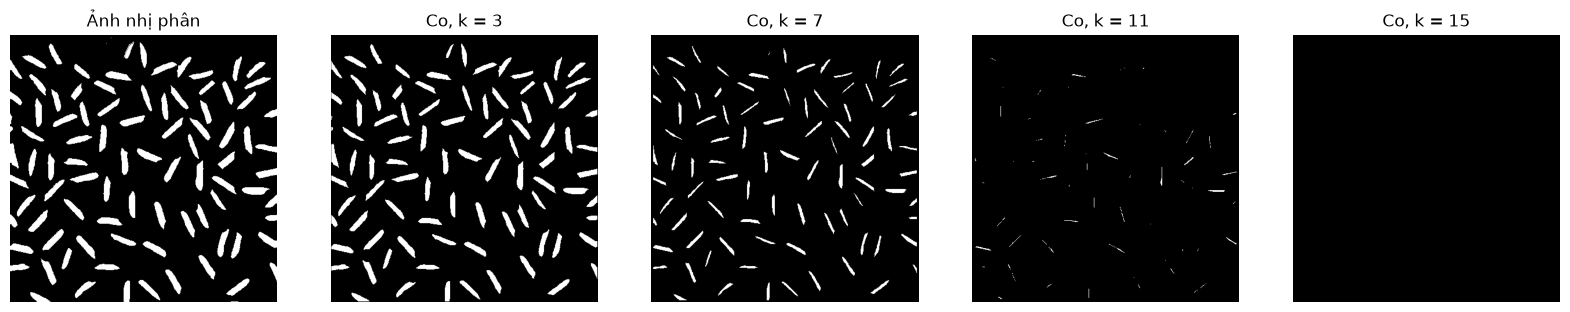

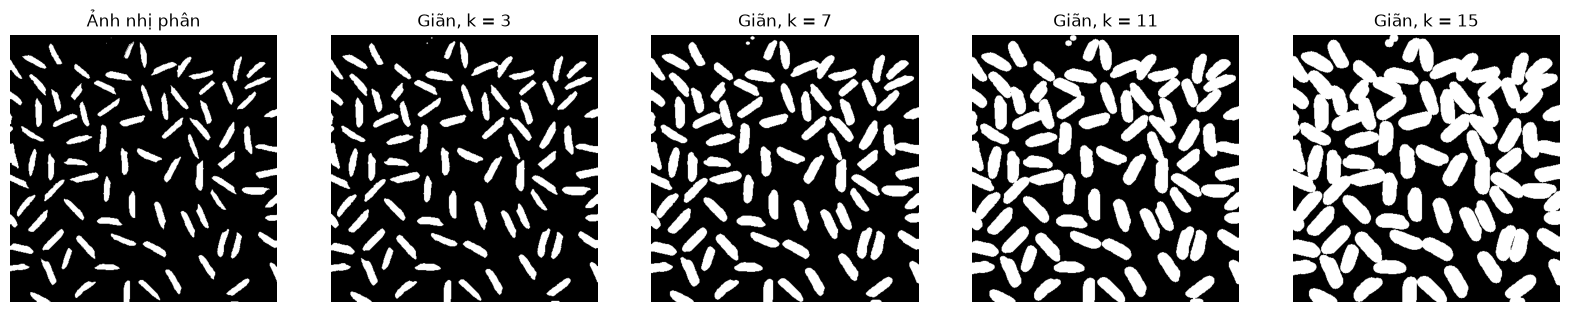

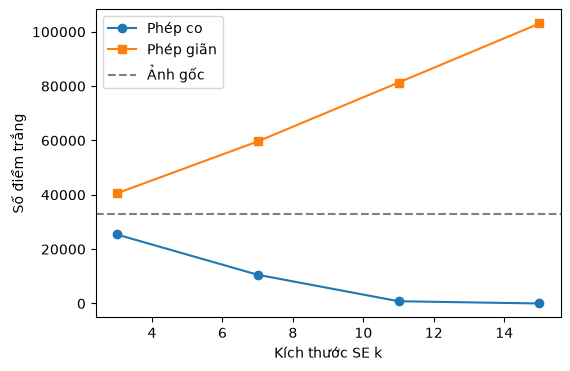

Số hạt: gốc = 90 | sau khi co k = 7: 87 | sau khi co k = 15: 0
Đúng: Số điểm trắng giảm dần khi co và tăng dần khi giãn
Đúng: Co với k = 15 làm mất bớt hạt gạo


In [10]:
rice = cv2.imread(os.path.join(IMG_DIR, 'gao3.png'), cv2.IMREAD_GRAYSCALE)
rice_bin = (rice > 10).astype(np.uint8)

def count_objects(binary, min_area=30):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary.astype(np.uint8), connectivity=8)
    return int((stats[1:, cv2.CC_STAT_AREA] >= min_area).sum())

ks = [3, 7, 11, 15]
eroded, dilated = [], []
for k in ks:
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    eroded.append(cv2.erode(rice_bin, se, borderType=cv2.BORDER_CONSTANT, borderValue=0))
    dilated.append(cv2.dilate(rice_bin, se, borderType=cv2.BORDER_CONSTANT, borderValue=0))

show([rice_bin] + eroded, ['Ảnh nhị phân'] + [f'Co, k = {k}' for k in ks], figsize=(20, 4))
show([rice_bin] + dilated, ['Ảnh nhị phân'] + [f'Giãn, k = {k}' for k in ks], figsize=(20, 4))
plt.figure(figsize=(6, 4))
plt.plot(ks, [int(e.sum()) for e in eroded], 'o-', label='Phép co')
plt.plot(ks, [int(d.sum()) for d in dilated], 's-', label='Phép giãn')
plt.axhline(int(rice_bin.sum()), color='gray', ls='--', label='Ảnh gốc')
plt.xlabel('Kích thước SE k'); plt.ylabel('Số điểm trắng'); plt.legend(); plt.show()
print('Số hạt: gốc =', count_objects(rice_bin), '| sau khi co k = 7:', count_objects(eroded[1]), '| sau khi co k = 15:', count_objects(eroded[3]))
check('Số điểm trắng giảm dần khi co và tăng dần khi giãn', lambda: all(eroded[i].sum() > eroded[i + 1].sum() and dilated[i].sum() < dilated[i + 1].sum() for i in range(3)))
check('Co với k = 15 làm mất bớt hạt gạo', lambda: count_objects(eroded[3]) < count_objects(rice_bin))


**Nhận xét:** Kết quả đếm được 90 hạt ở ảnh gốc và 87 hạt sau co với `k=7`; co với `k=15` làm mất cả 90 thành phần có diện tích từ 30 pixel trở lên. SE lớn loại được cả các hạt nhỏ và làm mất các chỗ nối hẹp, nên số thành phần giảm mạnh. Phép giãn làm đối tượng lớn lên và có thể nối các hạt gần nhau; khi giãn quá mức, nhiều hạt dính thành một thành phần nên số hạt đếm được giảm.

## Câu 2: Phép mở và phép đóng
### 2.1. Cài đặt và kiểm tra
- Phép mở: `A ∘ B = (A ⊖ B) ⊕ B` — làm trơn đường bao, cắt eo hẹp, loại bỏ mảnh nhỏ.
- Phép đóng: `A • B = (A ⊕ B) ⊖ B` — làm trơn đường bao, nối khe hẹp, lấp lỗ nhỏ.

OpenCV: `cv2.morphologyEx(src, cv2.MORPH_OPEN, kernel)` và `cv2.MORPH_CLOSE` — https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga67493776e3ad1a3df63883829375201f

Yêu cầu:
- Viết `my_open(A, B)`, `my_close(A, B)` dựa trên `my_erode`, `my_dilate`.
- Kiểm tra với **Câu 7.T4** (mở bằng SE vuông 3×3) và **Câu 7.T5** (đóng bằng SE chữ thập).
- Với ảnh của **Câu 7.T6**, kiểm tra hai tính chất: `A ∘ B ⊆ A ⊆ A • B` và tính lũy đẳng `(A ∘ B) ∘ B = A ∘ B`, `(A • B) • B = A • B`.

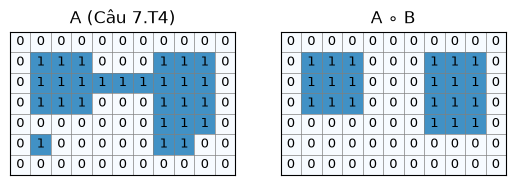

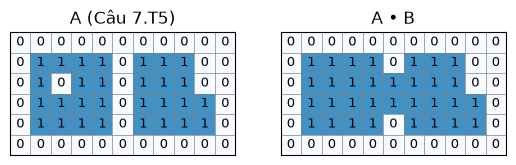

Đúng: Câu 7.T4: A ∘ B
Đúng: Câu 7.T5: A • B


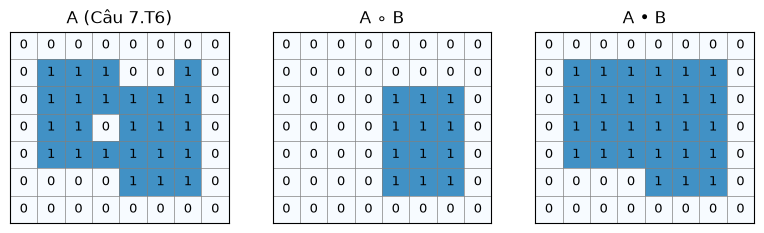

Đúng: Câu 7.T6: A ∘ B ⊆ A ⊆ A • B
Đúng: Câu 7.T6: mở và đóng có tính lũy đẳng


In [11]:
def my_open(A, B):
    return my_dilate(my_erode(A, B), B)

def my_close(A, B):
    return my_erode(my_dilate(A, B), B)

A_T4 = np.array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0], [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0], [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0], [0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
A_T5 = np.array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0], [0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0], [0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0], [0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
show_matrix([A_T4, my_open(A_T4, B_square)], ['A (Câu 7.T4)', 'A ∘ B'])
show_matrix([A_T5, my_close(A_T5, B_cross)], ['A (Câu 7.T5)', 'A • B'])
check('Câu 7.T4: A ∘ B', lambda: np.array_equal(my_open(A_T4, B_square), [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0], [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0], [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]))
check('Câu 7.T5: A • B', lambda: np.array_equal(my_close(A_T5, B_cross), [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0], [0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0], [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0], [0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]))

A_T6 = np.array([[0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 0, 0, 1, 0], [0, 1, 1, 1, 1, 1, 1, 0], [0, 1, 1, 0, 1, 1, 1, 0], [0, 1, 1, 1, 1, 1, 1, 0], [0, 0, 0, 0, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
O6 = my_open(A_T6, B_square)
C6 = my_close(A_T6, B_square)
inclusion_ok = bool(np.all(O6 <= A_T6) and np.all(A_T6 <= C6))
idempotent_ok = bool(np.array_equal(my_open(O6, B_square), O6) and np.array_equal(my_close(C6, B_square), C6))
show_matrix([A_T6, O6, C6], ['A (Câu 7.T6)', 'A ∘ B', 'A • B'])
check('Câu 7.T6: A ∘ B ⊆ A ⊆ A • B', lambda: inclusion_ok is True)
check('Câu 7.T6: mở và đóng có tính lũy đẳng', lambda: idempotent_ok is True)


### 2.2. Khử nhiễu “muối tiêu” trên ảnh nhị phân
Đoạn code dưới tạo ảnh sạch `clean` (hạt gạo sau khi mở nhẹ) và ảnh nhiễu `noisy`: 3% điểm nền bị đổi thành 1 (nhiễu muối), 10% điểm hạt gạo bị đổi thành 0 (nhiễu tiêu).

Yêu cầu:
- Viết hàm `denoise(mask, order, k)` với `order` là một trong `'open'`, `'close'`, `'open-close'`, `'close-open'`; dùng SE elip `k×k` và `cv2.morphologyEx`.
- Tính **tỉ lệ điểm sai** (%) so với `clean` cho 4 cách và `k = 3, 5`; in bảng kết quả và hiển thị kết quả tốt nhất.

Tỉ lệ điểm sai của ảnh nhiễu: 4.01%
       open, k = 3: 2.66%
      close, k = 3: 3.10%
 open-close, k = 3: 1.72%
 close-open, k = 3: 0.68%
       open, k = 5: 8.37%
      close, k = 5: 5.32%
 open-close, k = 5: 7.89%
 close-open, k = 5: 2.06%


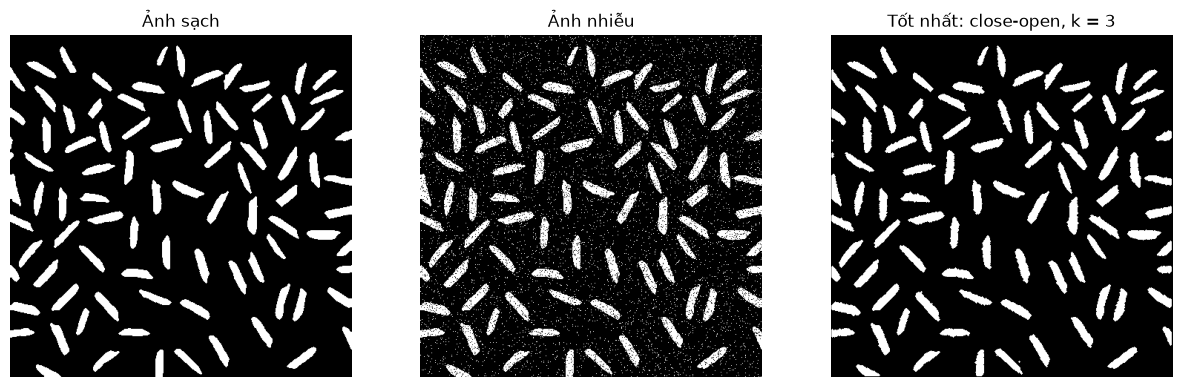

Đúng: Cách tốt nhất giảm tỉ lệ điểm sai xuống dưới 1,5%


In [12]:
se3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
clean = cv2.morphologyEx(rice_bin, cv2.MORPH_OPEN, se3)
rng = np.random.default_rng(7)
r = rng.random(clean.shape)
noisy = clean.copy()
noisy[(clean == 0) & (r < 0.03)] = 1
noisy[(clean == 1) & (r < 0.10)] = 0
error = lambda m: 100.0 * np.mean(m != clean)
print(f'Tỉ lệ điểm sai của ảnh nhiễu: {error(noisy):.2f}%')

def denoise(mask, order, k):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    operations = {
        'open': [cv2.MORPH_OPEN],
        'close': [cv2.MORPH_CLOSE],
        'open-close': [cv2.MORPH_OPEN, cv2.MORPH_CLOSE],
        'close-open': [cv2.MORPH_CLOSE, cv2.MORPH_OPEN],
    }
    if order not in operations:
        raise ValueError("order phải là 'open', 'close', 'open-close' hoặc 'close-open'")
    result = (np.asarray(mask) != 0).astype(np.uint8)
    for op in operations[order]:
        result = cv2.morphologyEx(result, op, se, borderType=cv2.BORDER_CONSTANT, borderValue=0)
    return result

results = {}
for k in [3, 5]:
    for order in ['open', 'close', 'open-close', 'close-open']:
        out = denoise(noisy, order, k)
        results[(order, k)] = error(out)
for key, v in results.items():
    print(f'{key[0]:>11s}, k = {key[1]}:', f'{v:.2f}%')
best = min(results, key=results.get)
show([clean, noisy, denoise(noisy, *best)], ['Ảnh sạch', 'Ảnh nhiễu', f'Tốt nhất: {best[0]}, k = {best[1]}'], figsize=(15, 5))
check('Cách tốt nhất giảm tỉ lệ điểm sai xuống dưới 1,5%', lambda: results[best] < 1.5)


**Nhận xét:** Tỉ lệ sai ban đầu là **4,01%**. Với `k=3`, `close-open` tốt nhất (**0,68%**), tiếp theo là `open-close` (1,72%), mở (2,66%) và đóng (3,10%). Với `k=5`, `close-open` vẫn tốt nhất nhưng sai số tăng lên **2,06%**; các cách còn lại có sai số 5,32–8,37%. Phép mở loại chấm trắng nền nhưng làm mất điểm foreground; phép đóng lấp nhiễu đen bên trong hạt nhưng có thể giữ nhiễu trắng. Đóng trước giúp khôi phục các lỗ đen, sau đó mở dọn nhiễu trắng. SE 5×5 làm biến dạng hạt nhiều hơn SE 3×3, vì vậy dù giữ đúng thứ tự, kết quả vẫn kém hơn.

## Câu 3: Các thuật toán xử lý hình thái
### 3.1. Tách biên
Công thức: `β(A) = A − (A ⊖ B)`.

Yêu cầu:
- Viết hàm `boundary(A, B)` dùng `cv2.erode` với **đệm 0** (giữ quy ước bài tính tay).
- Kiểm tra với **Câu 7.T7** (SE vuông 3×3, đáp số 32 điểm biên) và **Câu 7.T8** (so sánh SE vuông và chữ thập: 14 và 12 điểm).
- Áp dụng cho ảnh `clean` (hạt gạo): vẽ biên màu đỏ chồng lên ảnh gốc, so sánh số điểm biên khi dùng SE vuông và chữ thập. So sánh với `cv2.MORPH_GRADIENT` (= giãn − co).

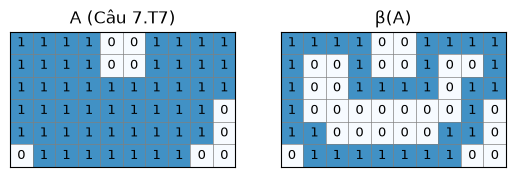

Đúng: Câu 7.T7: β(A) đúng và có 32 điểm
Đúng: Câu 7.T8: biên với SE vuông có 14 điểm, với SE chữ thập có 12 điểm


In [13]:
def boundary(A, B):
    A = (np.asarray(A) != 0).astype(np.uint8)
    eroded = cv2.erode(A, np.asarray(B, dtype=np.uint8), borderType=cv2.BORDER_CONSTANT, borderValue=0)
    return A & (1 - eroded)

A_T7 = np.array([[1, 1, 1, 1, 0, 0, 1, 1, 1, 1], [1, 1, 1, 1, 0, 0, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 0], [0, 1, 1, 1, 1, 1, 1, 1, 0, 0]], dtype=np.uint8)
show_matrix([A_T7, boundary(A_T7, B_square)], ['A (Câu 7.T7)', 'β(A)'])
check('Câu 7.T7: β(A) đúng và có 32 điểm', lambda: np.array_equal(boundary(A_T7, B_square), [[1, 1, 1, 1, 0, 0, 1, 1, 1, 1], [1, 0, 0, 1, 0, 0, 1, 0, 0, 1], [1, 0, 0, 1, 1, 1, 1, 0, 1, 1], [1, 0, 0, 0, 0, 0, 0, 0, 1, 0], [1, 1, 0, 0, 0, 0, 0, 1, 1, 0], [0, 1, 1, 1, 1, 1, 1, 1, 0, 0]]))
A_T8 = np.array([[0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 1, 0, 0], [0, 1, 1, 1, 1, 1, 0], [0, 1, 1, 1, 1, 1, 0], [0, 0, 1, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
check('Câu 7.T8: biên với SE vuông có 14 điểm, với SE chữ thập có 12 điểm',
      lambda: (int(boundary(A_T8, B_square).sum()), int(boundary(A_T8, B_cross).sum())) == (14, 12))


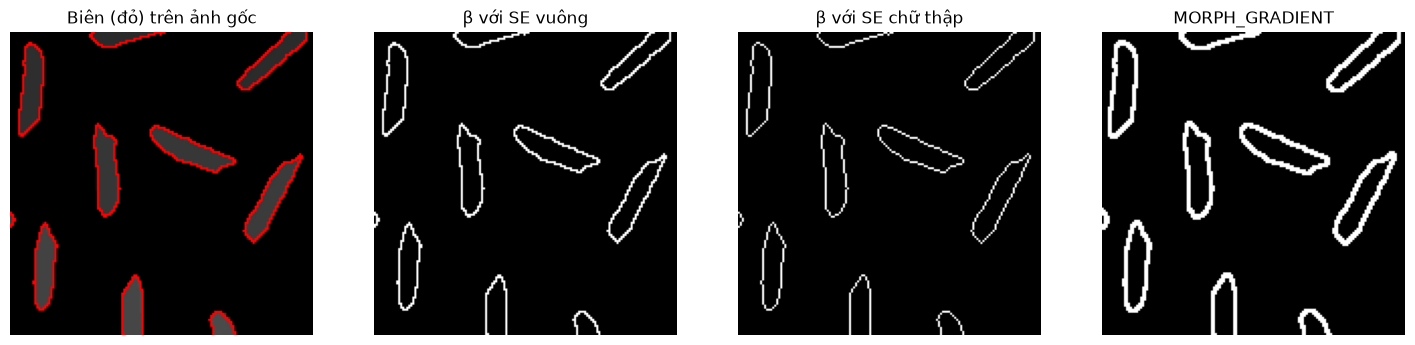

Số điểm biên: SE vuông = 10351 | SE chữ thập = 7285 | gradient = 21232
Đúng: Biên với SE vuông nhiều điểm hơn SE chữ thập, gradient dày nhất


In [14]:
b_square = boundary(clean, B_square)
b_cross = boundary(clean, B_cross)
gradient = cv2.morphologyEx(clean, cv2.MORPH_GRADIENT, B_square, borderType=cv2.BORDER_CONSTANT, borderValue=0)
# Đổi ảnh xám sang RGB trước khi tô biên đỏ để màu hiển thị đúng với matplotlib.
overlay = cv2.cvtColor(rice, cv2.COLOR_GRAY2RGB)
overlay[b_square != 0] = [255, 0, 0]
show([overlay[150:300, 150:300], b_square[150:300, 150:300], b_cross[150:300, 150:300], gradient[150:300, 150:300]],
     ['Biên (đỏ) trên ảnh gốc', 'β với SE vuông', 'β với SE chữ thập', 'MORPH_GRADIENT'], cmap='gray', figsize=(18, 5))
print('Số điểm biên: SE vuông =', int(b_square.sum()), '| SE chữ thập =', int(b_cross.sum()), '| gradient =', int(gradient.sum()))
check('Biên với SE vuông nhiều điểm hơn SE chữ thập, gradient dày nhất',
      lambda: b_cross.sum() < b_square.sum() < gradient.sum())


**Nhận xét:** Với SE chữ thập, biên lấy theo láng giềng 4 hướng; với SE vuông, phép co xét cả láng giềng chéo nên biên chịu ảnh hưởng của liên thông 8 hướng. Trên ảnh gạo, biên trong `A − erosion(A)` có **7.285 điểm** với SE chữ thập và **10.351 điểm** với SE vuông. `MORPH_GRADIENT` có **21.232 điểm**, khoảng **2,05 lần** biên SE vuông, vì lấy cả dải phía ngoài lẫn phía trong đường bao (`dilation − erosion`); ở các chỗ hẹp và cong, độ dày không đồng đều.

### 3.2. Làm đầy vùng (region filling)
Công thức: `Xₖ = (Xₖ₋₁ ⊕ B) ∩ Aᶜ`, `k = 1, 2, …`, lặp đến khi `Xₖ = Xₖ₋₁`; kết quả là `Xₖ ∪ A`. Ở đây `A` là ảnh **đường biên**, `X₀` chứa các điểm bắt đầu nằm trong vùng cần tô.

Yêu cầu:
- Viết hàm `region_fill(A, seeds, B)` trả về `(kết_quả, lịch_sử)` với `lịch_sử` là danh sách `[X₀, X₁, …]` (không lặp lại phần tử cuối). Dùng `cv2.dilate` với đệm 0.
- Kiểm tra với **Câu 7.T9** (điểm bắt đầu (3,3) tức `(2, 2)` trong Python; SE chữ thập; đáp án dừng ở `X₅`) và quan sát hiện tượng **tràn** khi dùng SE vuông.
- Kiểm tra với **Câu 7.T10** (hai điểm bắt đầu (3,3) và (4,9)).

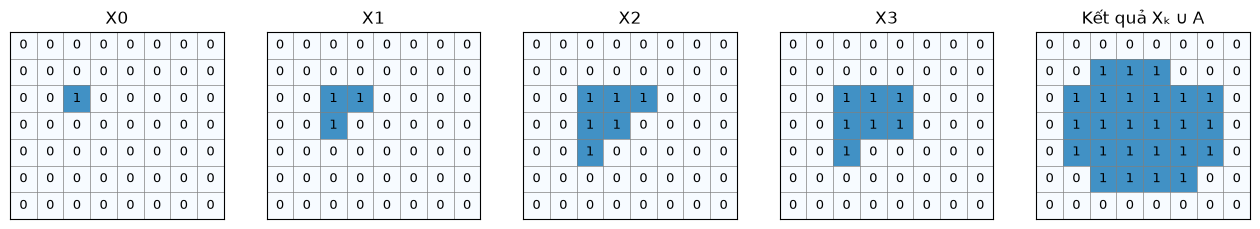

Đúng: Câu 7.T9: kết quả đúng, dừng ở X5


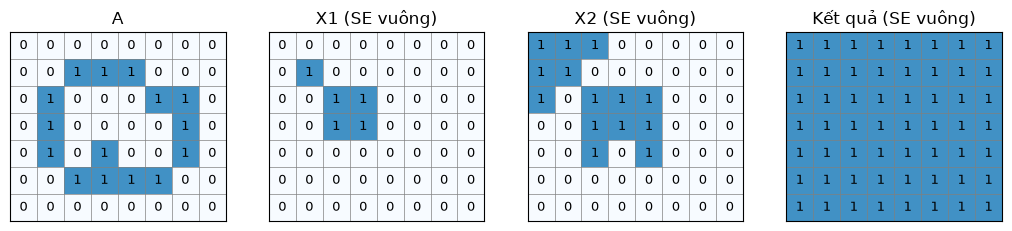

Đúng: Câu 7.T9c: SE vuông làm vùng tô tràn ra toàn ảnh
Đúng: Câu 7.T10a: tô đầy cả hai vùng (thêm 10 điểm, dừng ở X2)


In [15]:
def region_fill(A, seeds, B):
    A = (np.asarray(A) != 0).astype(np.uint8)
    B = (np.asarray(B) != 0).astype(np.uint8)
    X = np.zeros_like(A)
    for (r, c) in seeds:
        X[r, c] = 1
    X &= 1 - A
    history = [X.copy()]
    while True:
        expanded = cv2.dilate(X, B, borderType=cv2.BORDER_CONSTANT, borderValue=0)
        X_next = expanded & (1 - A)
        if np.array_equal(X_next, X):
            break
        X = X_next
        history.append(X.copy())
    return X | A, history

A_T9 = np.array([[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 1, 1, 0, 0, 0], [0, 1, 0, 0, 0, 1, 1, 0], [0, 1, 0, 0, 0, 0, 1, 0], [0, 1, 0, 1, 0, 0, 1, 0], [0, 0, 1, 1, 1, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
F9, H9 = region_fill(A_T9, [(2, 2)], B_cross)
show_matrix(H9[:4] + [F9], [f'X{k}' for k in range(4)] + ['Kết quả Xₖ ∪ A'])
check('Câu 7.T9: kết quả đúng, dừng ở X5', lambda: np.array_equal(F9, [[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 1, 1, 0, 0, 0], [0, 1, 1, 1, 1, 1, 1, 0], [0, 1, 1, 1, 1, 1, 1, 0], [0, 1, 1, 1, 1, 1, 1, 0], [0, 0, 1, 1, 1, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0]]) and len(H9) == 6)
F9s, H9s = region_fill(A_T9, [(2, 2)], B_square)
show_matrix([A_T9, H9s[1], H9s[2], F9s], ['A', 'X1 (SE vuông)', 'X2 (SE vuông)', 'Kết quả (SE vuông)'])
check('Câu 7.T9c: SE vuông làm vùng tô tràn ra toàn ảnh', lambda: F9s.min() == 1)
A_T10 = np.array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0], [0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1], [0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1], [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
F10, H10 = region_fill(A_T10, [(2, 2), (3, 8)], B_cross)
check('Câu 7.T10a: tô đầy cả hai vùng (thêm 10 điểm, dừng ở X2)', lambda: int(F10.sum() - A_T10.sum()) == 10 and len(H10) == 3)


#### Áp dụng: đếm số ô màu trên mặt khối Rubik
Trong ảnh `rubik/rub00.jpg`, các ô màu được bao quanh bởi khung nhựa màu đen. Ta coi khung đen là “đường biên” `A`; mỗi ô màu là một vùng kín cần tô.

Yêu cầu:
1. Tạo mặt nạ khung đen `frame`: chuyển sang HSV, làm mờ Gaussian 5×5, lấy kênh V và tách ngưỡng `V < 80`; sau đó **đóng** với SE vuông 5×5 để nối các chỗ khung bị đứt.
2. Dùng `region_fill` với một điểm bắt đầu ở **tâm ảnh** để tô ô màu chính giữa.
3. Tô **tất cả** các ô cùng lúc với một điểm bắt đầu duy nhất: thêm viền 1 điểm ảnh bằng 0 quanh `frame`, chọn điểm bắt đầu ở góc `(0, 0)` (nằm ở nền ngoài), làm đầy vùng → `Xₖ` là toàn bộ nền ngoài; khi đó các ô màu chính là `1 − (Xₖ ∪ frame)` (xem Câu 7.T10c). Viết thành hàm `fill_holes(mask)` trả về mặt nạ đã lấp hết lỗ.
4. Đếm số ô màu bằng `cv2.connectedComponentsWithStats` (bỏ các thành phần nhỏ hơn 1% diện tích ảnh).

Gợi ý: với ảnh lớn, `region_fill` lặp vài trăm lần nhưng mỗi lần chỉ là một lệnh `cv2.dilate`, vẫn đủ nhanh.

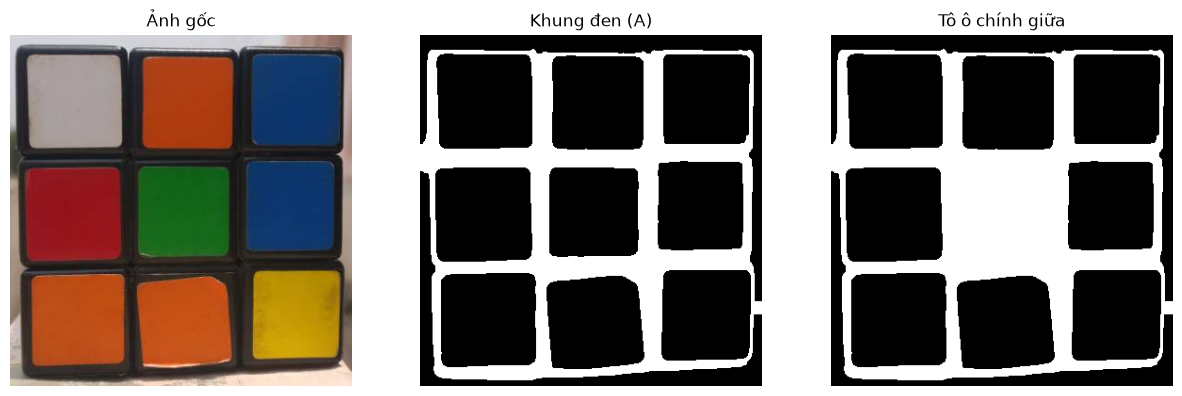

In [16]:
rub = cv2.imread(os.path.join(IMG_DIR, 'rubik', 'rub00.jpg'))
hsv = cv2.cvtColor(rub, cv2.COLOR_BGR2HSV)
blurred_v = cv2.GaussianBlur(hsv[:, :, 2], (5, 5), 0)
frame = (blurred_v < 80).astype(np.uint8)
frame = cv2.morphologyEx(frame, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
center = (frame.shape[0] // 2, frame.shape[1] // 2)
one_cell, _ = region_fill(frame, [center], B_cross)
show([cv2.cvtColor(rub, cv2.COLOR_BGR2RGB), frame, one_cell], ['Ảnh gốc', 'Khung đen (A)', 'Tô ô chính giữa'], cmap='gray', figsize=(15, 5))


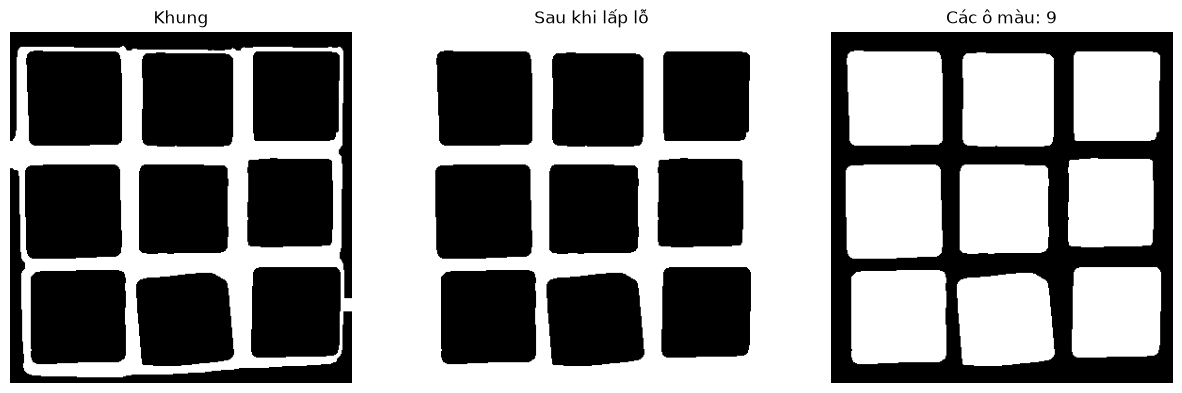

Đúng: Đếm được 9 ô màu


In [17]:
def fill_holes(mask):
    # Lấp các lỗ kín bằng cách tô nền ngoài trên ảnh đã đệm.
    mask = (np.asarray(mask) != 0).astype(np.uint8)
    padded = np.pad(mask, 1, mode='constant', constant_values=0)
    exterior_filled, _ = region_fill(padded, [(0, 0)], B_cross)
    return exterior_filled[1:-1, 1:-1]

filled = fill_holes(frame)
cells_raw = 1 - filled
n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(cells_raw.astype(np.uint8), connectivity=8)
min_area = 0.01 * cells_raw.size
cells = np.zeros_like(cells_raw)
kept = [idx for idx in range(1, n_labels) if stats[idx, cv2.CC_STAT_AREA] >= min_area]
for idx in kept:
    cells[labels == idx] = 1
n_cells = len(kept)
show([frame, filled, cells], ['Khung', 'Sau khi lấp lỗ', f'Các ô màu: {n_cells}'], figsize=(15, 5))
check('Đếm được 9 ô màu', lambda: n_cells == 9)


### 3.3. Trích xuất thành phần liên thông
Công thức: `Xₖ = (Xₖ₋₁ ⊕ B) ∩ A`, lặp đến khi `Xₖ = Xₖ₋₁`. SE vuông 3×3 cho liên thông 8, SE chữ thập cho liên thông 4.

Yêu cầu:
- Viết `extract_component(A, seed, B)` trả về mặt nạ thành phần chứa `seed`.
- Viết `label_components(A, B)` gán nhãn **tất cả** các thành phần: lặp lại việc chọn một điểm 1 chưa có nhãn → trích thành phần → gán nhãn mới. Trả về `(số_thành_phần, ảnh_nhãn)`.
- Kiểm tra với **Câu 7.T11** và so sánh với `cv2.connectedComponents(A, connectivity=8 / 4)`.
- Đếm số hạt gạo trong ảnh `clean` bằng hàm của bạn và bằng OpenCV.

Đúng: Câu 7.T11a: thành phần chứa (2,2) với SE vuông có 5 điểm
Đúng: Câu 7.T11b: với SE chữ thập chỉ còn 3 điểm


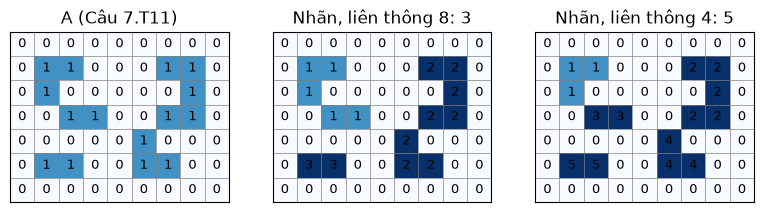

Đúng: Câu 7.T11d: 3 thành phần (liên thông 8) và 5 thành phần (liên thông 4)
Đúng: Khớp với cv2.connectedComponents


In [18]:
def extract_component(A, seed, B):
    A = (np.asarray(A) != 0).astype(np.uint8)
    B = (np.asarray(B) != 0).astype(np.uint8)
    X = np.zeros_like(A)
    if A[seed] == 0:
        return X
    X[seed] = 1
    while True:
        expanded = cv2.dilate(X, B, borderType=cv2.BORDER_CONSTANT, borderValue=0)
        X_next = expanded & A
        if np.array_equal(X_next, X):
            return X
        X = X_next

def label_components(A, B):
    A = (np.asarray(A) != 0).astype(np.uint8)
    labels = np.zeros(A.shape, dtype=np.int32)
    n = 0
    while True:
        remaining = (A != 0) & (labels == 0)
        if not np.any(remaining):
            break
        seed = tuple(np.argwhere(remaining)[0])
        component = extract_component(A, seed, B)
        n += 1
        labels[component != 0] = n
    return n, labels

A_T11 = np.array([[0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 1, 0, 0, 0, 1, 1, 0], [0, 1, 0, 0, 0, 0, 0, 1, 0], [0, 0, 1, 1, 0, 0, 1, 1, 0], [0, 0, 0, 0, 0, 1, 0, 0, 0], [0, 1, 1, 0, 0, 1, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=np.uint8)
check('Câu 7.T11a: thành phần chứa (2,2) với SE vuông có 5 điểm', lambda: int(extract_component(A_T11, (1, 1), B_square).sum()) == 5)
check('Câu 7.T11b: với SE chữ thập chỉ còn 3 điểm', lambda: int(extract_component(A_T11, (1, 1), B_cross).sum()) == 3)
n8, lab8 = label_components(A_T11, B_square)
n4, lab4 = label_components(A_T11, B_cross)
show_matrix([A_T11, lab8, lab4], ['A (Câu 7.T11)', f'Nhãn, liên thông 8: {n8}', f'Nhãn, liên thông 4: {n4}'])
check('Câu 7.T11d: 3 thành phần (liên thông 8) và 5 thành phần (liên thông 4)', lambda: (n8, n4) == (3, 5))
check('Khớp với cv2.connectedComponents', lambda: (cv2.connectedComponents(A_T11, connectivity=8)[0] - 1,
                                                    cv2.connectedComponents(A_T11, connectivity=4)[0] - 1) == (n8, n4))


Hàm tự viết: 90 hạt (0.23 s) | OpenCV: 90 hạt (0.4 ms)


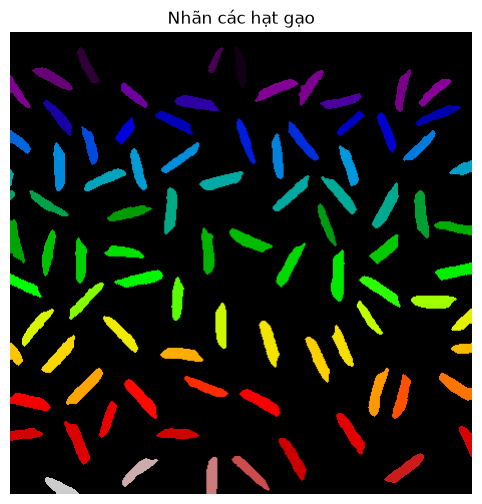

Đúng: Số hạt đếm bằng hàm tự viết bằng OpenCV


In [19]:
import time
t = time.time()
n_rice, lab_rice = label_components(clean, B_square)
t_mine = time.time() - t
t = time.time()
n_cv = cv2.connectedComponents(clean, connectivity=8)[0] - 1
t_cv = time.time() - t
print(f'Hàm tự viết: {n_rice} hạt ({t_mine:.2f} s) | OpenCV: {n_cv} hạt ({t_cv * 1000:.1f} ms)')
plt.figure(figsize=(6, 6)); plt.imshow(lab_rice, cmap='nipy_spectral'); plt.title('Nhãn các hạt gạo'); plt.axis('off'); plt.show()
check('Số hạt đếm bằng hàm tự viết bằng OpenCV', lambda: n_rice == n_cv)

## Câu 4: Tách các đối tượng dính nhau bằng phép co
Phép co làm **tách rời các đối tượng gần nhau** (slide 14). Ảnh tổng hợp `coins` dưới đây có 12 đồng xu, trong đó nhiều đồng xu chạm hoặc chồng lên nhau nên đếm thành phần liên thông trực tiếp sẽ sai.

Yêu cầu:
1. Đếm số thành phần của `coins`. Sau đó co ảnh với SE elip `k×k`, `k = 3, 7, …, 43`, đếm số thành phần sau mỗi lần co và vẽ đồ thị số thành phần theo `k`.
2. Chọn `k` nhỏ nhất cho đúng 12 thành phần; dùng các thành phần sau khi co làm **hạt giống (marker)**, rồi “mọc” lại từng hạt giống bằng **phép giãn có điều kiện** trong `coins` (giống công thức trích thành phần liên thông nhưng nhiều hạt giống cùng mọc, điểm nào đã có nhãn thì không gán lại) để được ảnh nhãn của 12 đồng xu.
3. Nhận xét: vì sao với một số giá trị `k` số thành phần lại **lớn hơn** 12? Vì sao `k` quá lớn thì số thành phần giảm?

Số thành phần ban đầu: 9 | số đồng xu thật: 12
Số thành phần theo k: {3: 10, 7: 10, 11: 10, 15: 10, 19: 11, 23: 13, 27: 12, 31: 12, 35: 12, 39: 12, 43: 12}


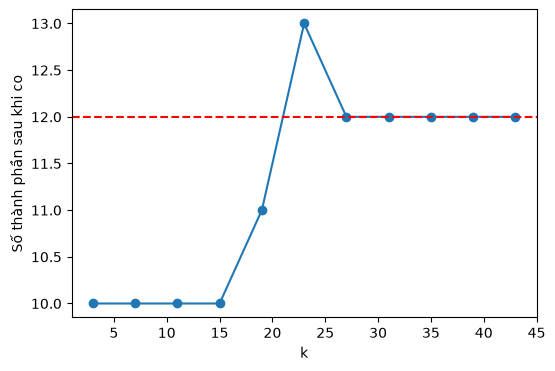

In [20]:
def make_coins():
    img = np.zeros((300, 420), np.uint8)
    circles = [(60, 60, 32), (118, 66, 30), (220, 60, 26), (300, 70, 34), (362, 60, 28),
               (70, 170, 28), (125, 190, 30), (100, 238, 26), (230, 180, 38), (300, 200, 30),
               (370, 170, 22), (370, 250, 24)]
    for (x, y, r) in circles:
        cv2.circle(img, (x, y), r, 1, -1)
    return img, len(circles)

coins, N_COINS = make_coins()
print('Số thành phần ban đầu:', cv2.connectedComponents(coins, connectivity=8)[0] - 1, '| số đồng xu thật:', N_COINS)

ks = list(range(3, 44, 4))
counts = []
for k in ks:
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    eroded_coins = cv2.erode(coins, se, borderType=cv2.BORDER_CONSTANT, borderValue=0)
    counts.append(cv2.connectedComponents(eroded_coins, connectivity=8)[0] - 1)
print('Số thành phần theo k:', dict(zip(ks, counts)))
plt.figure(figsize=(6, 4)); plt.plot(ks, counts, 'o-'); plt.axhline(N_COINS, color='r', ls='--')
plt.xlabel('k'); plt.ylabel('Số thành phần sau khi co'); plt.show()


k được chọn: 27


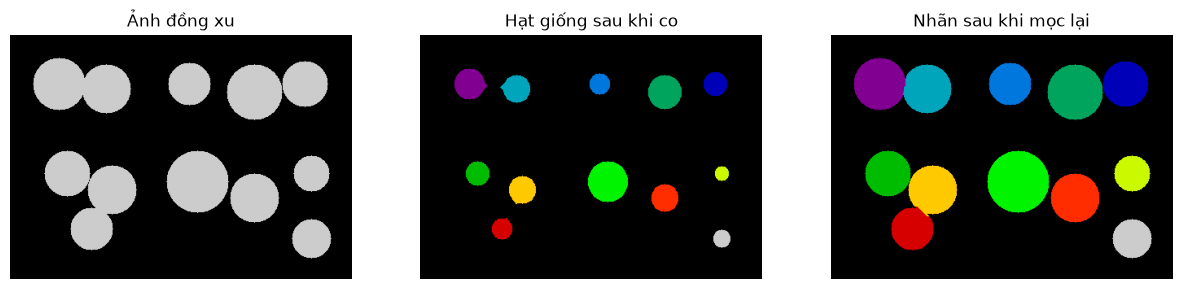

Đúng: Tách được đúng 12 đồng xu, phủ kín ảnh gốc


In [21]:
def grow_markers(markers, mask):
    # Giãn có điều kiện nhiều hạt giống cùng lúc trong mask.
    labels = markers.astype(np.int32).copy()
    mask = (np.asarray(mask) != 0).astype(np.uint8)
    cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
    while True:
        before = labels.copy()
        # Mỗi nhãn lan một bước; ô đã được gán nhãn được giữ nguyên.
        for label_id in range(1, int(labels.max()) + 1):
            region = (labels == label_id).astype(np.uint8)
            grown = cv2.dilate(region, cross, borderType=cv2.BORDER_CONSTANT, borderValue=0)
            labels[(grown != 0) & (mask != 0) & (labels == 0)] = label_id
        if np.array_equal(labels, before):
            break
    return labels

# Chọn k nhỏ nhất có đúng 12 mảnh sau phép co, rồi gán từng mảnh làm marker.
k_best = next(k for k, n in zip(ks, counts) if n == N_COINS)
se_best = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_best, k_best))
eroded_best = cv2.erode(coins, se_best, borderType=cv2.BORDER_CONSTANT, borderValue=0)
_, markers = cv2.connectedComponents(eroded_best, connectivity=8)
coin_labels = grow_markers(markers, coins)
print('k được chọn:', k_best)
show([coins, markers, coin_labels], ['Ảnh đồng xu', 'Hạt giống sau khi co', 'Nhãn sau khi mọc lại'], cmap='nipy_spectral', figsize=(15, 4))
check('Tách được đúng 12 đồng xu, phủ kín ảnh gốc', lambda: coin_labels.max() == N_COINS and np.array_equal(coin_labels > 0, coins > 0))


**Nhận xét:** Ảnh ban đầu có 9 thành phần dù chứa 12 đồng xu vì một số đồng xu chạm nhau. Số thành phần sau co lần lượt là `{3: 10, 7: 10, 11: 10, 15: 10, 19: 11, 23: 13, 27: 12, 31: 12, 35: 12, 39: 12, 43: 12}`. Từ `k=23`, một số đồng xu bị co tách thành nhiều mảnh nên số thành phần vượt 12; khi `k` quá lớn, các marker nhỏ có thể biến mất. `k=27` là giá trị nhỏ nhất trong dãy thử cho đúng 12 marker; giãn có điều kiện từ các marker này phủ lại đúng vùng đồng xu ban đầu.

## Câu 5: Đếm ô màu trên toàn bộ ảnh Rubik
Thư mục `images/rubik` có 10 ảnh `rub00.jpg` … `rub09.jpg` chụp mặt Rubik với điều kiện chiếu sáng khác nhau (cùng bộ ảnh với bài tập không gian màu chương 1).

Yêu cầu:
1. Viết hàm `count_cells_global(img, T=80)` theo đúng các bước ở Mục 3.2 và chạy trên cả 10 ảnh. Có bao nhiêu ảnh đếm đúng 9 ô? Hiển thị một ảnh đếm sai và giải thích nguyên nhân.
2. Cải tiến bằng phép **black-hat** `cv2.MORPH_BLACKHAT` (= đóng(ảnh) − ảnh), làm nổi các chi tiết **tối và mảnh** hơn SE bất kể độ sáng nền: tính black-hat của kênh V với SE elip lớn (ví dụ 71×71), tách ngưỡng Otsu để được khung, đóng 7×7, lấp lỗ, mở 9×9 để làm sạch các ô, chỉ giữ thành phần có diện tích từ 3% đến 20% ảnh. So sánh số ảnh đếm đúng với cách 1.
3. Nhận xét: còn những ảnh nào sai, vì sao? Đề xuất hướng cải tiến tiếp.

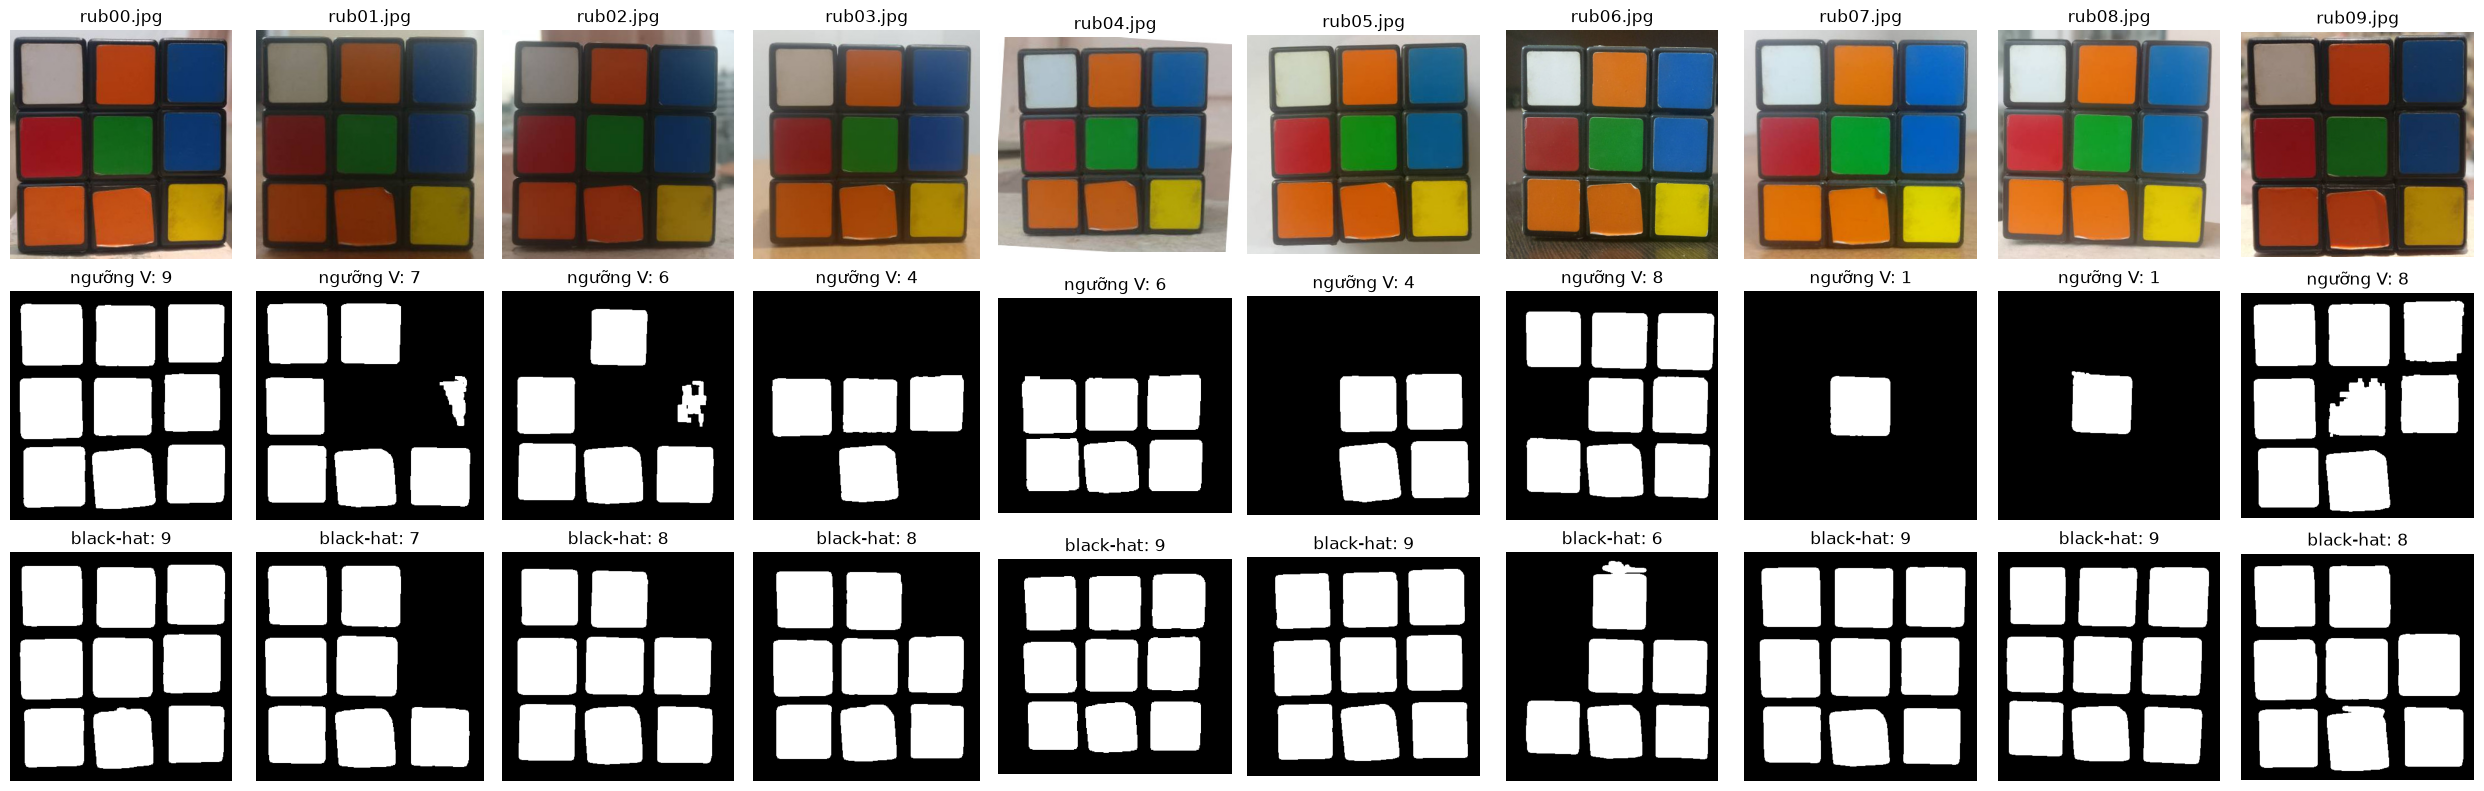

Số ảnh đếm đúng 9 ô: ngưỡng V toàn cục = 1/10, black-hat = 5/10
rub00.jpg: ngưỡng V=9, black-hat=9
rub01.jpg: ngưỡng V=7, black-hat=7
rub02.jpg: ngưỡng V=6, black-hat=8
rub03.jpg: ngưỡng V=4, black-hat=8
rub04.jpg: ngưỡng V=6, black-hat=9
rub05.jpg: ngưỡng V=4, black-hat=9
rub06.jpg: ngưỡng V=8, black-hat=6
rub07.jpg: ngưỡng V=1, black-hat=9
rub08.jpg: ngưỡng V=1, black-hat=9
rub09.jpg: ngưỡng V=8, black-hat=8
Đúng: Black-hat đếm đúng nhiều ảnh hơn ngưỡng toàn cục


In [22]:
rubik_files = sorted(glob.glob(os.path.join(IMG_DIR, 'rubik', '*.jpg')))

def _cells_from_frame(frame, min_fraction=0.01, max_fraction=1.0, opening_size=None):
    frame = (np.asarray(frame) != 0).astype(np.uint8)
    filled = fill_holes(frame)
    cells = 1 - filled
    if opening_size is not None:
        se_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (opening_size, opening_size))
        cells = cv2.morphologyEx(cells, cv2.MORPH_OPEN, se_open, borderType=cv2.BORDER_CONSTANT, borderValue=0)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(cells.astype(np.uint8), connectivity=8)
    lo, hi = min_fraction * cells.size, max_fraction * cells.size
    kept = [i for i in range(1, n) if lo <= stats[i, cv2.CC_STAT_AREA] <= hi]
    result = np.zeros_like(cells)
    for i in kept:
        result[labels == i] = 1
    return len(kept), result

def count_cells_global(img, T=80):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    value = cv2.GaussianBlur(hsv[:, :, 2], (5, 5), 0)
    frame = (value < T).astype(np.uint8)
    frame = cv2.morphologyEx(frame, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8),
                             borderType=cv2.BORDER_CONSTANT, borderValue=0)
    return _cells_from_frame(frame, min_fraction=0.01)

def count_cells_blackhat(img, k=71):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    value = cv2.GaussianBlur(hsv[:, :, 2], (5, 5), 0)
    se_bh = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    blackhat = cv2.morphologyEx(value, cv2.MORPH_BLACKHAT, se_bh)
    _, frame = cv2.threshold(blackhat, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    frame = cv2.morphologyEx(frame, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8),
                             borderType=cv2.BORDER_CONSTANT, borderValue=0)
    return _cells_from_frame(frame, min_fraction=0.03, max_fraction=0.20, opening_size=9)

res_global, res_bh = [], []
fig, axes = plt.subplots(3, 10, figsize=(25, 8))
for i, f in enumerate(rubik_files):
    img = cv2.imread(f)
    c1, m1 = count_cells_global(img)
    c2, m2 = count_cells_blackhat(img)
    res_global.append(c1); res_bh.append(c2)
    axes[0, i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, i].set_title(os.path.basename(f))
    if m1 is not None: axes[1, i].imshow(m1, cmap='gray')
    if m2 is not None: axes[2, i].imshow(m2, cmap='gray')
    axes[1, i].set_title(f'ngưỡng V: {c1}'); axes[2, i].set_title(f'black-hat: {c2}')
    for ax in axes[:, i]: ax.axis('off')
plt.tight_layout(); plt.show()
ok1 = sum(c == 9 for c in res_global); ok2 = sum(c == 9 for c in res_bh)
print(f'Số ảnh đếm đúng 9 ô: ngưỡng V toàn cục = {ok1}/10, black-hat = {ok2}/10')
for name, c1, c2 in zip([os.path.basename(f) for f in rubik_files], res_global, res_bh):
    print(f'{name}: ngưỡng V={c1}, black-hat={c2}')
check('Black-hat đếm đúng nhiều ảnh hơn ngưỡng toàn cục', lambda: ok2 > ok1)


**Nhận xét:** Ngưỡng V toàn cục đếm đúng **1/10 ảnh** (chỉ `rub00.jpg`); black-hat đếm đúng **5/10**: `rub00`, `rub04`, `rub05`, `rub07`, `rub08`. Số ô mà hai cách đếm được lần lượt là: `rub00` 9/9, `rub01` 7/7, `rub02` 6/8, `rub03` 4/8, `rub04` 6/9, `rub05` 4/9, `rub06` 8/6, `rub07` 1/9, `rub08` 1/9, `rub09` 8/8 (ngưỡng V / black-hat). Tất cả trường hợp sai đều đếm thiếu, phù hợp với việc khung bị đứt hoặc các ô dính thành vùng lớn, hay vùng nhỏ bị loại bởi lọc diện tích. Black-hat cải thiện rõ ở `rub07` và `rub08`, nhưng vẫn không khắc phục được mọi điều kiện chiếu sáng; `rub06` còn giảm từ 8 xuống 6. Có thể cải tiến bằng hiệu chỉnh sáng cục bộ, chọn kích thước SE theo tỉ lệ ảnh, rồi dùng cấu trúc lưới 3×3 và vị trí/kích thước tương đối của từng ô để kiểm tra thay vì chỉ dựa vào ngưỡng và diện tích.